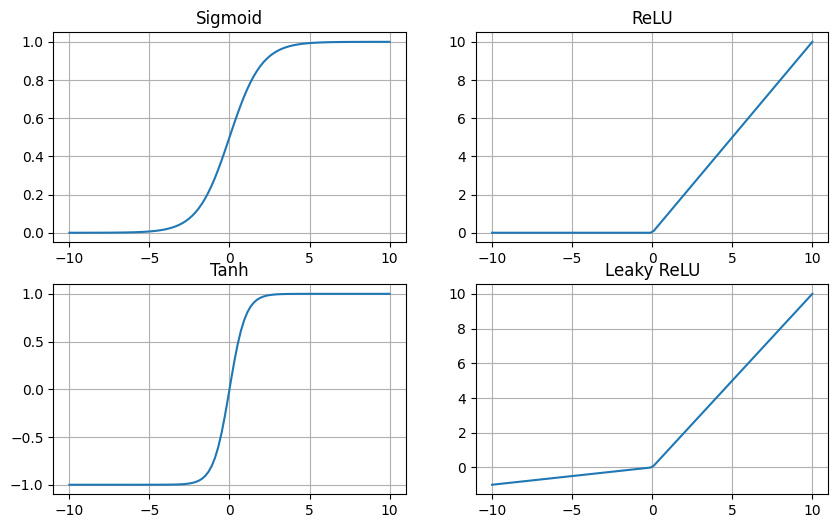

In [12]:
# Q.1)  
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 100)

funct = {
    'Sigmoid': 1 / (1 + np.exp(-x)),
    'ReLU': np.maximum(0, x),
    'Tanh': np.tanh(x),
    'Leaky ReLU': np.where(x > 0, x, 0.1 * x)
}

# Plot the functions
plt.figure(figsize=(10, 6))
for i, (n, y) in enumerate(funct.items(), 1):
    plt.subplot(2, 2, i)
    plt.plot(x, y)
    plt.title(n)
    plt.grid(True)


plt.show()

Accuracy: 0.5
Prediction for '4': -1


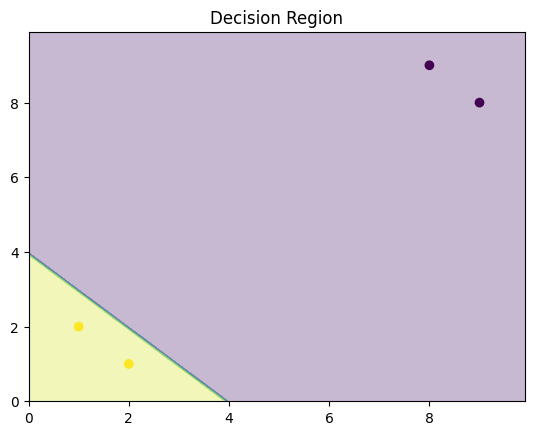

In [13]:
# Q.2) and Q.3)
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Perceptron


X = np.array([[ord(str(i))] for i in range(10)])  
y = np.array([1 if i % 2 == 0 else -1 for i in range(10)])
model = Perceptron()
model.fit(X, y)

print("Accuracy:", model.score(X, y))
print("Prediction for '4':", model.predict([[ord('4')]])[0])
X2 = np.array([[1, 2], [2, 1], [8, 9], [9, 8]])
y2 = np.array([1, 1, -1, -1])

model2 = Perceptron().fit(X2, y2)

xx, yy = np.meshgrid(np.arange(0, 10, 0.1),
                     np.arange(0, 10, 0.1))

grid = np.array([xx.ravel(), yy.ravel()]).transpose()
Z = model2.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X2[:, 0], X2[:, 1], c=y2)
plt.title("Decision Region")
plt.show()

In [14]:
# Q.4) 

import numpy as np

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([[0], [1], [1], [0]])

np.random.seed(1)
W1 = np.random.rand(2, 2)
W2 = np.random.rand(2, 1)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_d(x):
    return x * (1 - x)

for epoch in range(5000):
    hid = sigmoid(np.dot(X, W1))
    out = sigmoid(np.dot(hid, W2))
    error = y - out
    
    d_out = error * sigmoid_d(out)
    d_hid = d_out.dot(W2.T) * sigmoid_d(hid)
    W2 += hid.T.dot(d_out)
    W1 += X.T.dot(d_hid)

print("Final Output:\n", out)

Final Output:
 [[0.05652694]
 [0.89514443]
 [0.89514415]
 [0.13920602]]


In [15]:
# Q.5)

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN

X = np.array([[0,0], [0,1], [1,0], [1,1]])
y = np.array([0, 1, 1, 0])

ffnn = Sequential()
ffnn.add(Dense(4, input_dim=2, activation='relu'))
ffnn.add(Dense(1, activation='sigmoid'))
ffnn.compile(loss='binary_crossentropy', optimizer='adam')
ffnn.fit(X, y, epochs=200, verbose=0)
ffnn_pred = ffnn.predict(X)

X_rnn = np.array([[[0],[1]], [[1],[0]], [[1],[1]], [[0],[0]]])
y_rnn = np.array([1, 1, 0, 0])

rnn = Sequential()
rnn.add(SimpleRNN(4, input_shape=(2,1), activation='tanh'))
rnn.add(Dense(1, activation='sigmoid'))
rnn.compile(loss='binary_crossentropy', optimizer='adam')
rnn.fit(X_rnn, y_rnn, epochs=200, verbose=0)
rnn_pred = rnn.predict(X_rnn)

print("Final Output:")
print("FFNN Predictions:\n", ffnn_pred)
print("RNN Predictions:\n", rnn_pred)

C:\Users\ASUS ROG\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


C:\Users\ASUS ROG\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Final Output:
FFNN Predictions:
 [[0.47084025]
 [0.6844168 ]
 [0.4059486 ]
 [0.45002857]]
RNN Predictions:
 [[0.48094252]
 [0.5876675 ]
 [0.49472448]
 [0.44287494]]


In [16]:
# Q.6) Easy
import tensorflow as tf
from tensorflow.keras import layers, models


(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()


X_train, X_test = X_train/255.0, X_test/255.0
X_train = X_train.reshape(-1,28,28,1)
X_test = X_test.reshape(-1,28,28,1)

model = models.Sequential([
    layers.Conv2D(32, 3, activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')
])


model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=2, verbose=0)


print("Accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

C:\Users\ASUS ROG\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Accuracy: 0.9745000004768372


In [17]:
# Q.6) Moderate

import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

X_train, X_test = X_train/255.0, X_test/255.0
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

model = models.Sequential()
model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)))
model.add(layers.MaxPooling2D((2,2)))
model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))   # extra layer for better learning
model.add(layers.Dense(10, activation='softmax'))

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=3, verbose=1)

loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

pred = model.predict(X_test[:5])
print("Predicted:", np.argmax(pred, axis=1))
print("Actual:", y_test[:5])

Epoch 1/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9510 - loss: 0.1620
Epoch 2/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 7ms/step - accuracy: 0.9822 - loss: 0.0577
Epoch 3/3
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9885 - loss: 0.0383
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9862 - loss: 0.0428
Test Accuracy: 0.9861999750137329
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
Predicted: [7 2 1 0 4]
Actual: [7 2 1 0 4]


In [18]:
# Q.7) Easy

import tensorflow as tf
from tensorflow.keras import layers, models, datasets

(X_train, y_train), (X_test, y_test) = datasets.cifar10.load_data()   # CIFAR-10 fdataset

X_train, X_test = X_train / 255.0, X_test / 255.0

model = models.Sequential([
    layers.Conv2D(32, 3, activation='relu', input_shape=(32, 32, 3)),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(10, activation='softmax')
])

model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=3, verbose=0)


print("CIFAR-10 Accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

CIFAR-10 Accuracy: 0.6104000210762024


In [19]:
# Q.7) Moderate

import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()
X_train, X_test = X_train/255.0, X_test/255.0

model = models.Sequential()
model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(32,32,3)))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D((2,2)))

model.add(layers.Flatten())
model.add(layers.Dense(64, activation='relu'))
model.add(layers.Dense(10, activation='softmax'))  # 10 classes

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=3, verbose=1)

loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

pred = model.predict(X_test[:5])
print("Predicted:", np.argmax(pred, axis=1).flatten())
print("Actual:", y_test[:5].flatten())

Epoch 1/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.4807 - loss: 1.4502
Epoch 2/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.6199 - loss: 1.0911
Epoch 3/3
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 18s 11ms/step - accuracy: 0.6657 - loss: 0.9683
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.6676 - loss: 0.9753
Test Accuracy: 0.6675999760627747
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step
Predicted: [3 8 8 0 4]
Actual: [3 8 8 0 6]


In [21]:
# Q.8) Easy 

import tensorflow as tf
from tensorflow.keras import layers, models, datasets
from tensorflow.keras.preprocessing.sequence import pad_sequences

(X_train, y_train), (X_test, y_test) = datasets.imdb.load_data(num_words=10000)


X_train = pad_sequences(X_train, maxlen=100)
X_test = pad_sequences(X_test, maxlen=100)


model = models.Sequential([

    layers.Embedding(input_dim=10000, output_dim=32, input_length=100),
    layers.SimpleRNN(32, activation='tanh'),
    layers.Dense(1, activation='sigmoid') 
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.fit(X_train, y_train, epochs=3, batch_size=128, verbose=0)
print("RNN Sentiment Accuracy:", model.evaluate(X_test, y_test, verbose=0)[1])

RNN Sentiment Accuracy: 0.8369600176811218


In [1]:
# Q.8) Moderate 

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense
from tensorflow.keras.preprocessing.sequence import pad_sequences


(X_train, y_train), (X_test, y_test) = tf.keras.datasets.imdb.load_data(num_words=10000)
X_train = pad_sequences(X_train, maxlen=200)
X_test = pad_sequences(X_test, maxlen=200)

model = Sequential()
model.add(Embedding(input_dim=10000, output_dim=32, input_length=200))
model.add(SimpleRNN(32))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam',
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.fit(X_train, y_train, epochs=3, batch_size=64, verbose=1)

loss, acc = model.evaluate(X_test, y_test)
print("Test Accuracy:", acc)

Epoch 1/3


C:\Users\ASUS ROG\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


391/391 ━━━━━━━━━━━━━━━━━━━━ 15s 33ms/step - accuracy: 0.7174 - loss: 0.5405
Epoch 2/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 21s 35ms/step - accuracy: 0.8694 - loss: 0.3185
Epoch 3/3
391/391 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - accuracy: 0.8685 - loss: 0.3083
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.6960 - loss: 0.5775
Test Accuracy: 0.6959999799728394


In [3]:
# Q.9) Easy

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense


X = np.array([
    [10, 20, 30], 
    [20, 30, 40], 
    [30, 40, 50], 
    [40, 50, 60], 
    [50, 60, 70]
])
y = np.array([40, 50, 60, 70, 80]) 
X = X.reshape((5, 3, 1))

model = Sequential([
    LSTM(50, activation='relu', input_shape=(3, 1)),
    Dense(1) # Predicts a single continuous number
])

model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=200, verbose=0)

new_weather = np.array([60, 70, 80]).reshape((1, 3, 1))

prediction = model.predict(new_weather, verbose=0)
print(f"Forecasted Next Value: {np.round(prediction[0][0])}")

C:\Users\ASUS ROG\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Forecasted Next Value: 93.0


In [22]:
# Q.9) Moderate

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

data = np.array([i for i in range(50)])

X, y = [], []
for i in range(len(data)-3):
    X.append(data[i:i+3])   
    y.append(data[i+3])     

X = np.array(X)
y = np.array(y)
X = X.reshape((X.shape[0], X.shape[1], 1))

model = Sequential()
model.add(LSTM(50, activation='relu', input_shape=(3,1)))
model.add(Dense(1))

model.compile(optimizer='adam', loss='mse')
model.fit(X, y, epochs=200, verbose=0)

test_input = np.array([[47, 48, 49]]).reshape((1,3,1))
pred = model.predict(test_input)

print("Predicted next value:", pred[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step
Predicted next value: 50.064686


In [25]:
# Q.10)  Easy

import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.datasets import mnist


(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 784) / 255.0
X_test = X_test.reshape(-1, 784) / 255.0

model = Sequential([
    Dense(32, activation='relu', input_shape=(784,)),
    Dense(784, activation='sigmoid') 
])
model.compile(optimizer='adam', loss='mse')
model.fit(X_train, X_train)
recon = model.predict(X_test)

error = np.mean(np.square(X_test - recon))
print("Reconstruction Error (MSE):", round(error, 4))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - loss: 0.0319
313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
Reconstruction Error (MSE): 0.0165


Epoch 1/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 15ms/step - loss: 0.1249
Epoch 2/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 21s 15ms/step - loss: 0.1025
Epoch 3/3
938/938 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - loss: 0.1005
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step


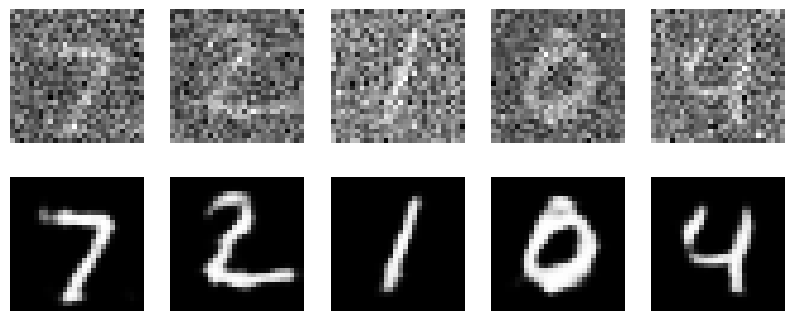

In [26]:
# Q.10) Moderate

import tensorflow as tf
from tensorflow.keras import layers, models
import numpy as np
import matplotlib.pyplot as plt

(trainX, trainY), (testX, testY) = tf.keras.datasets.mnist.load_data()

trainX = trainX / 255.0
testX = testX / 255.0
trainX = trainX.reshape(-1, 28, 28, 1)
testX = testX.reshape(-1, 28, 28, 1)

noise = 0.5
trainNoisy = trainX + noise * np.random.normal(size=trainX.shape)
testNoisy = testX + noise * np.random.normal(size=testX.shape)

model = models.Sequential([
    layers.Conv2D(32, 3, activation='relu', padding='same', input_shape=(28,28,1)),
    layers.MaxPooling2D(2, padding='same'),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.UpSampling2D(2),
    layers.Conv2D(1, 3, activation='sigmoid', padding='same')
])

model.compile(optimizer='adam', loss='binary_crossentropy')
model.fit(trainNoisy, trainX, epochs=3, batch_size=64, verbose=1)
output = model.predict(testNoisy[:5])
plt.figure(figsize=(10,4))
for i in range(5):
    plt.subplot(2,5,i+1)
    plt.imshow(testNoisy[i].reshape(28,28), cmap='gray')
    plt.axis('off')

    plt.subplot(2,5,i+6)
    plt.imshow(output[i].reshape(28,28), cmap='gray')
    plt.axis('off')

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


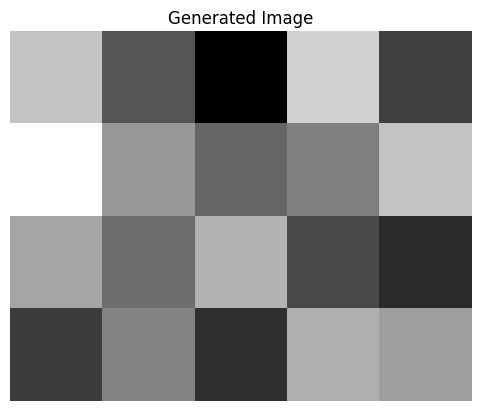

In [28]:
# Q.11)
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

gen = models.Sequential([
    layers.Dense(64, activation='relu', input_dim=10),
    layers.Dense(20, activation='sigmoid')   
])

disc = models.Sequential([
    layers.Dense(64, activation='relu', input_dim=20),
    layers.Dense(1, activation='sigmoid')
])
disc.compile(optimizer='adam', loss='binary_crossentropy')
disc.trainable = False
gan = models.Sequential([gen, disc])
gan.compile(optimizer='adam', loss='binary_crossentropy')

for i in range(200):
    real = np.random.rand(16, 20)
    noise = np.random.rand(16, 10)
    fake = gen.predict(noise, verbose=0)
    X = np.vstack([real, fake])
    y = np.vstack([np.ones((16,1)), np.zeros((16,1))])
    disc.trainable = True
    disc.train_on_batch(X, y)
    disc.trainable = False
    gan.train_on_batch(noise, np.ones((16,1)))

sample = gen.predict(np.random.rand(1,10))

plt.imshow(sample.reshape(4,5), cmap='gray')
plt.title("Generated Image")
plt.axis('off')
plt.show()